# Notebook 6 — Evaluación y Despliegue de Modelos
### Tecnologías Emergentes (ISO46B) — Material complementario de comprensión conceptual

Notebook **autocontenido** para **Google Colab** (`Entorno de ejecución > Ejecutar todas`). Usa el dataset **Digits** de `scikit-learn` (incluido en la librería, sin descargas).

**Objetivo:** ir más allá de la precisión (`accuracy`) como única métrica, entender el compromiso precisión/recall, y recorrer el flujo de **despliegue**: guardar un modelo entrenado, recargarlo, y exportarlo a un formato optimizado para producción.

Framework: **TensorFlow/Keras**.

## 0. Configuración inicial

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, precision_recall_curve,
)

sns.set_style("whitegrid")
np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 1. Entrenar un modelo de referencia

In [2]:
digitos = load_digits()
X, y = digitos.data, digitos.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
escalador = StandardScaler()
X_train = escalador.fit_transform(X_train)
X_test = escalador.transform(X_test)

modelo = keras.Sequential([
    layers.Input(shape=(64,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
modelo.fit(X_train, y_train, epochs=35, batch_size=32, validation_split=0.2, verbose=0)

perdida, precision_global = modelo.evaluate(X_test, y_test, verbose=0)
print(f"Precisión (accuracy) global en test: {precision_global:.4f}")

Precisión (accuracy) global en test: 0.9778


## 2. Más allá del *accuracy*: precisión, recall y F1

El *accuracy* puede ser engañoso, especialmente con clases desbalanceadas. Tres métricas complementarias, para cada clase:

- **Precisión** = de todo lo que el modelo predijo como clase X, ¿qué fracción era realmente clase X? (mide falsos positivos)
- **Recall (sensibilidad)** = de todo lo que realmente era clase X, ¿qué fracción detectó el modelo? (mide falsos negativos)
- **F1-score** = media armónica de precisión y recall — resume ambas en un solo número.

In [3]:
y_pred_probs = modelo.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      1.000     0.981     0.991        54
           1      0.947     0.982     0.964        55
           2      0.963     0.981     0.972        53
           3      1.000     1.000     1.000        55
           4      0.963     0.963     0.963        54
           5      1.000     0.964     0.981        55
           6      1.000     1.000     1.000        54
           7      0.964     1.000     0.982        54
           8      0.979     0.904     0.940        52
           9      0.964     1.000     0.982        54

    accuracy                          0.978       540
   macro avg      0.978     0.977     0.977       540
weighted avg      0.978     0.978     0.978       540



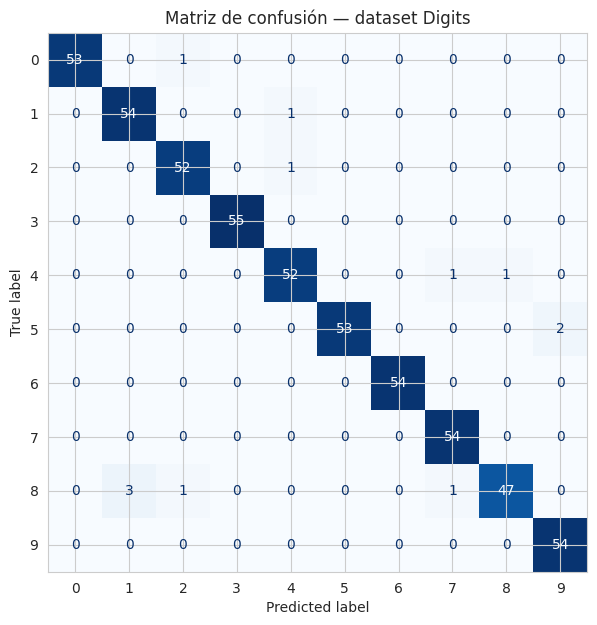

In [4]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Matriz de confusión — dataset Digits")
plt.show()

**Lectura:** la diagonal principal son los aciertos. Cualquier valor fuera de la diagonal es un error específico (ej. "un 3 real que el modelo confundió con un 8") — mucho más informativo que un solo número de accuracy.

## 3. Curva ROC y AUC (por clase, one-vs-rest)

La curva ROC muestra el compromiso entre la tasa de verdaderos positivos y la tasa de falsos positivos, a medida que varía el umbral de decisión. El área bajo la curva (**AUC**) resume ese compromiso en un solo número (1.0 = perfecto, 0.5 = azar).

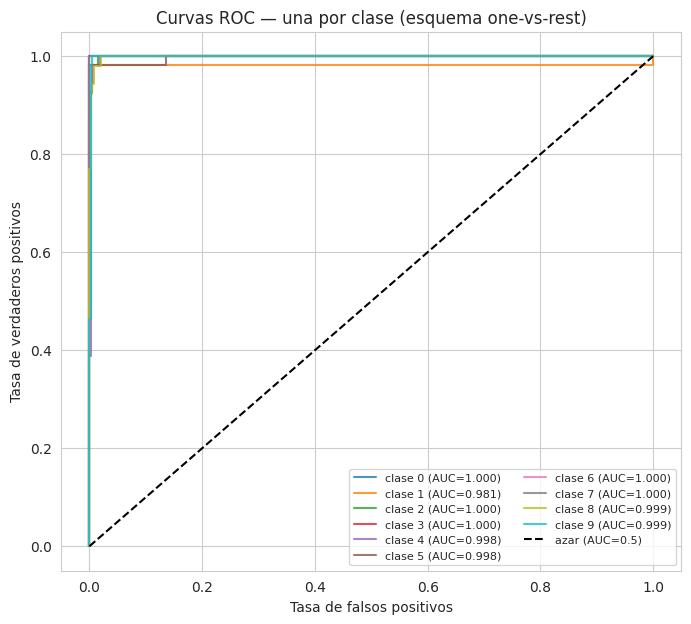

In [5]:
y_test_binario = label_binarize(y_test, classes=list(range(10)))

plt.figure(figsize=(8, 7))
for clase in range(10):
    fpr, tpr, _ = roc_curve(y_test_binario[:, clase], y_pred_probs[:, clase])
    area = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"clase {clase} (AUC={area:.3f})", alpha=0.8)

plt.plot([0, 1], [0, 1], "k--", label="azar (AUC=0.5)")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC — una por clase (esquema one-vs-rest)")
plt.legend(fontsize=8, ncol=2)
plt.show()

## 4. El compromiso precisión–recall y el umbral de decisión

Convertimos el problema en binario ("¿es un 5, o no?") para ver con claridad cómo **el umbral de decisión** desplaza el equilibrio entre precisión y recall.

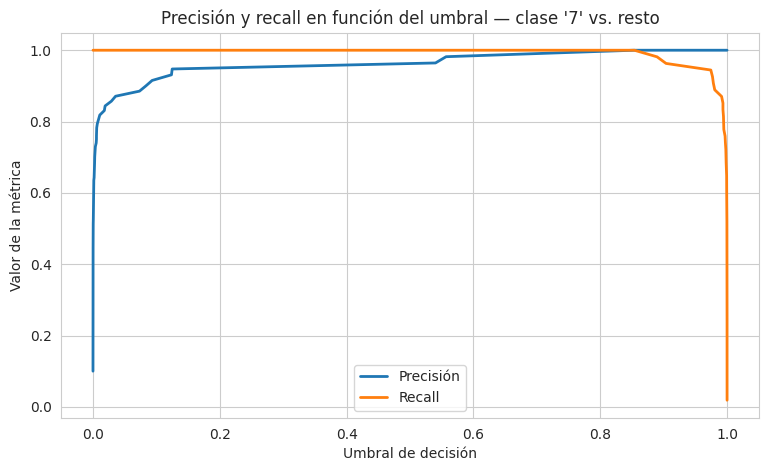

In [6]:
CLASE_OBJETIVO = 7
y_test_es_cinco = (y_test == CLASE_OBJETIVO).astype(int)
probs_clase_cinco = y_pred_probs[:, CLASE_OBJETIVO]

precisiones, recalls, umbrales = precision_recall_curve(y_test_es_cinco, probs_clase_cinco)

plt.figure(figsize=(9, 5))
plt.plot(umbrales, precisiones[:-1], label="Precisión", linewidth=2)
plt.plot(umbrales, recalls[:-1], label="Recall", linewidth=2)
plt.xlabel("Umbral de decisión")
plt.ylabel("Valor de la métrica")
plt.title(f"Precisión y recall en función del umbral — clase '{CLASE_OBJETIVO}' vs. resto")
plt.legend()
plt.show()

**Lectura y aplicación práctica:** subir el umbral aumenta la precisión (el modelo solo predice "sí" cuando está muy seguro) pero baja el recall (deja pasar más casos reales sin detectar). La elección del umbral depende del costo de cada tipo de error en la aplicación real — por ejemplo, en un sistema médico de detección se suele preferir alto recall (no dejar pasar casos reales) aunque baje algo la precisión.

## 5. Despliegue: guardar y recargar el modelo

Un modelo entrenado solo es útil si puede **guardarse** y **cargarse** después, en otro proceso o servidor, sin volver a entrenar.

In [7]:
os.makedirs("modelos_exportados", exist_ok=True)
ruta_modelo = "modelos_exportados/modelo_digits.keras"
modelo.save(ruta_modelo)

modelo_recargado = keras.models.load_model(ruta_modelo)

predicciones_originales = modelo.predict(X_test[:5], verbose=0)
predicciones_recargadas = modelo_recargado.predict(X_test[:5], verbose=0)

coinciden = np.allclose(predicciones_originales, predicciones_recargadas)
print(f"Tamaño del archivo guardado: {os.path.getsize(ruta_modelo) / 1024:.1f} KB")
print(f"¿Las predicciones del modelo recargado coinciden con el original?  {coinciden}")

Tamaño del archivo guardado: 101.9 KB
¿Las predicciones del modelo recargado coinciden con el original?  True


## 6. Exportar a un formato optimizado para producción (TensorFlow Lite)

Para desplegar en dispositivos con recursos limitados (móviles, microcontroladores, IoT), se convierte el modelo a un formato más compacto y rápido de ejecutar — **TensorFlow Lite**.

Saved artifact at '/tmp/tmpg5nb3cgf'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  134339827494224: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134339827495184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134339827494800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134339827495568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134339827495376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134339827494992: TensorSpec(shape=(), dtype=tf.resource, name=None)


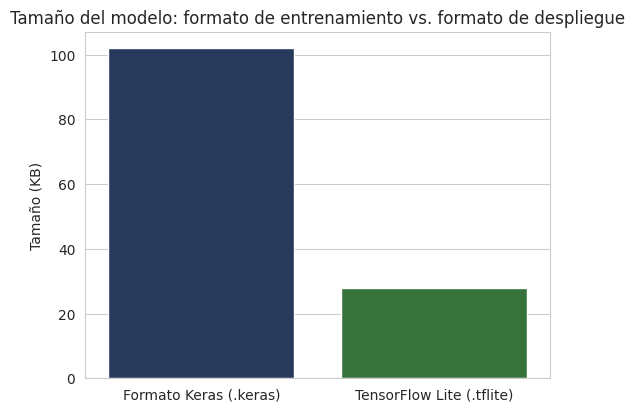

In [8]:
convertidor = tf.lite.TFLiteConverter.from_keras_model(modelo)
modelo_tflite = convertidor.convert()

ruta_tflite = "modelos_exportados/modelo_digits.tflite"
with open(ruta_tflite, "wb") as f:
    f.write(modelo_tflite)

tamano_keras = os.path.getsize(ruta_modelo) / 1024
tamano_tflite = os.path.getsize(ruta_tflite) / 1024

plt.figure(figsize=(6, 4.5))
sns.barplot(x=["Formato Keras (.keras)", "TensorFlow Lite (.tflite)"], y=[tamano_keras, tamano_tflite],
            hue=["Formato Keras (.keras)", "TensorFlow Lite (.tflite)"], palette=["#1F3864", "#2E7D32"], legend=False)
plt.ylabel("Tamaño (KB)")
plt.title("Tamaño del modelo: formato de entrenamiento vs. formato de despliegue")
plt.show()

In [9]:
interprete = tf.lite.Interpreter(model_content=modelo_tflite)
interprete.allocate_tensors()
detalles_entrada = interprete.get_input_details()
detalles_salida = interprete.get_output_details()

entrada_prueba = X_test[0:1].astype(np.float32)
interprete.set_tensor(detalles_entrada[0]["index"], entrada_prueba)
interprete.invoke()
salida_tflite = interprete.get_tensor(detalles_salida[0]["index"])

print("Predicción con el modelo Keras original: ", np.argmax(modelo.predict(entrada_prueba, verbose=0)))
print("Predicción con el modelo TFLite:          ", np.argmax(salida_tflite))
print("Etiqueta real:                            ", y_test[0])

Predicción con el modelo Keras original:  1
Predicción con el modelo TFLite:           1
Etiqueta real:                             1


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## 7. Portabilidad entre frameworks: el rol de ONNX

En este curso alternamos entre **TensorFlow/Keras** y **PyTorch**. En un entorno de producción real, a veces se necesita mover un modelo de un framework a otro (por ejemplo, entrenar en PyTorch pero desplegar en un sistema basado en TensorFlow, o viceversa). **ONNX** (Open Neural Network Exchange) es un formato intermedio estándar para esto:

```
 Modelo Keras  ──(tf2onnx)──▶  archivo .onnx  ──(onnx2torch)──▶  Modelo PyTorch
 Modelo PyTorch ──(torch.onnx.export)──▶  archivo .onnx  ──▶  TensorFlow, ONNX Runtime, etc.
```

- Desde **PyTorch**, se exporta con `torch.onnx.export(modelo, entrada_ejemplo, "modelo.onnx")`, o su forma equivalente **TorchScript** (`torch.jit.trace`/`torch.jit.script`) para desplegar el modelo sin depender del código fuente de Python.
- Desde **Keras**, se exporta con la librería `tf2onnx`.
- Una vez en formato `.onnx`, el modelo puede ejecutarse con **ONNX Runtime** en muchos lenguajes y plataformas distintas, independientemente del framework en que se entrenó.

Esta interoperabilidad es la razón por la que, en la práctica profesional, no hay que "elegir un solo framework para siempre" — cada uno se usa donde es más fuerte (investigación, producción, dispositivos móviles), y formatos como ONNX permiten moverse entre ellos.

## 8. Resumen

| Paso | Herramienta | Propósito |
|---|---|---|
| Métricas más allá de accuracy | `classification_report`, matriz de confusión | Diagnosticar errores por clase, no solo un promedio global |
| Curva ROC / AUC | `roc_curve`, `auc` | Evaluar el modelo independientemente de un umbral fijo |
| Curva precisión–recall | `precision_recall_curve` | Elegir el umbral según el costo real de cada tipo de error |
| Guardar / recargar | `model.save()`, `keras.models.load_model()` | Reutilizar un modelo entrenado sin reentrenar |
| TensorFlow Lite | `TFLiteConverter` | Desplegar en dispositivos con recursos limitados |
| ONNX / TorchScript | `torch.onnx.export`, `tf2onnx` | Portar modelos entre frameworks y plataformas |

Con esto se cierra el recorrido completo: preprocesamiento (Notebook 1) → arquitecturas (Notebooks 2–4) → entrenamiento y ajuste (Notebook 5) → evaluación y despliegue (este notebook) — el ciclo de vida completo de un proyecto de Machine Learning / Deep Learning.
